# New Dataset

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import sys
from pathlib import Path
project_dir = Path.cwd().parent
sys.path.insert(0, str(project_dir))
from src.sparsification import *

In [2]:
df = pd.read_csv("tree_cfs.csv")
T, taxa = build_tensor(df)

Experiment 1 - Baseline experiment involves testing different methods with a predetermined seed and number of samples

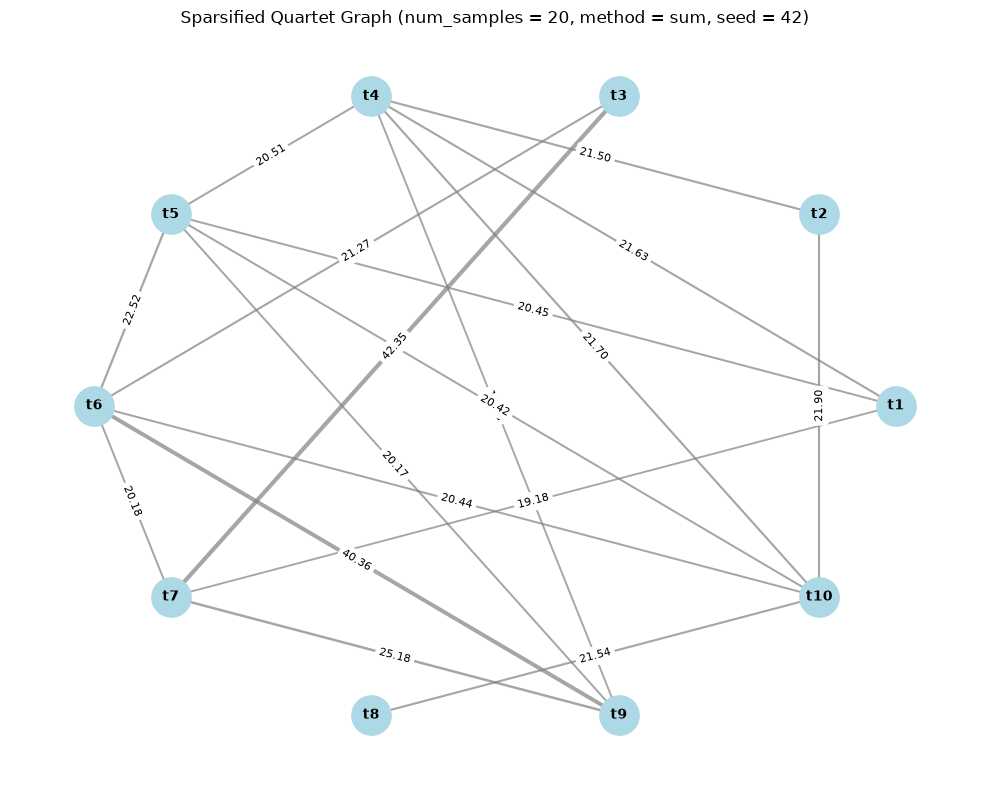

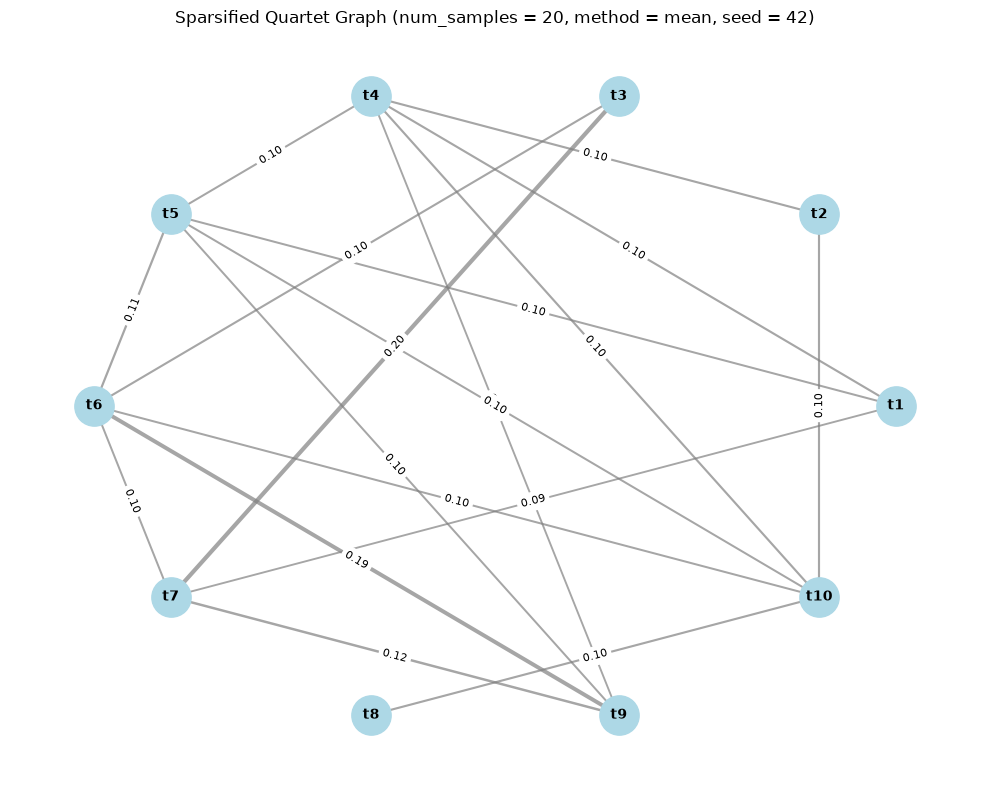

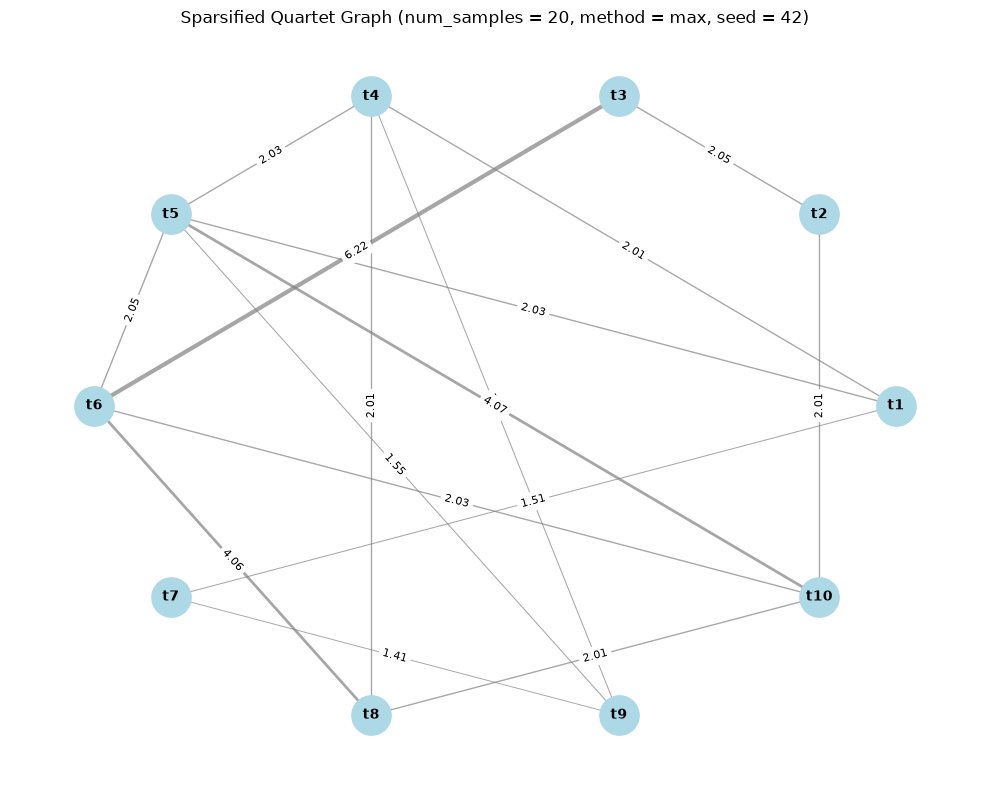

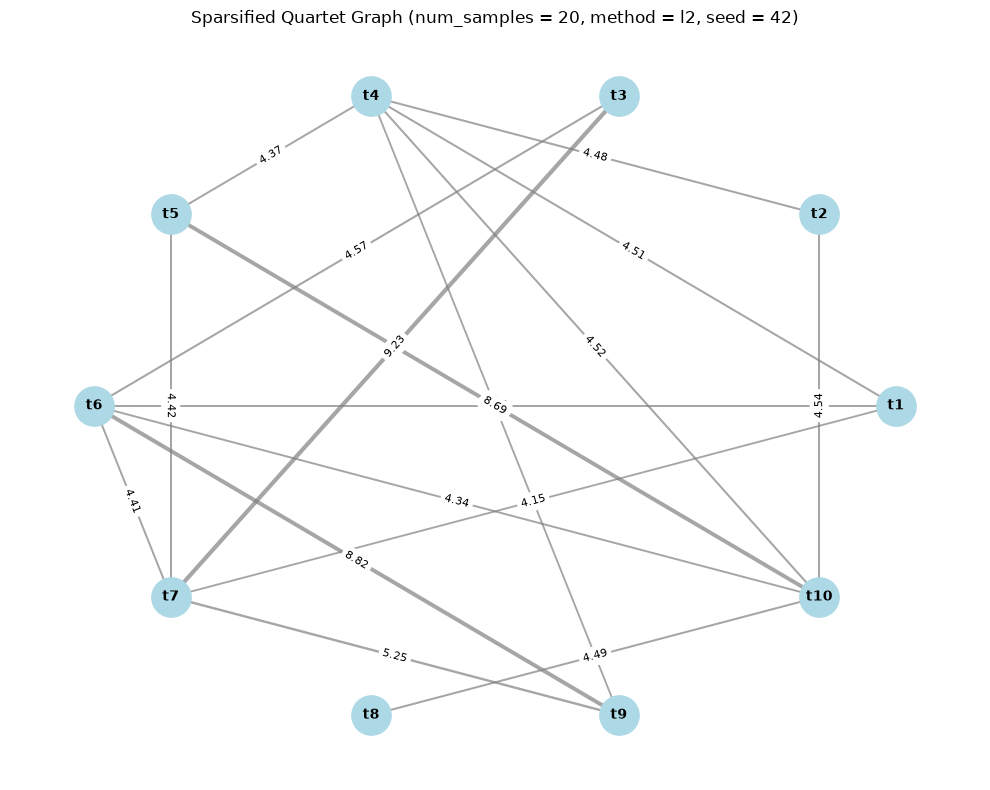

In [3]:
num_samples = 20
seed = 42

for method in ["sum", "mean", "max", "l2"]:

    W = collapse_tensor(T, method)
    L = compute_laplacian(W)
    R = compute_effective_resistance(L)
    edge_list = compute_edge_sampling_probabilities(
        W, R, taxa
    )
    W_sparse = sample_edges(
        edge_list,
        num_samples=num_samples,
        n=len(taxa),
        taxa=taxa,
        seed=seed
    )
    visualize_graph(W_sparse, taxa, num_samples, method, seed)

Experiment 2 with different number of num_samples

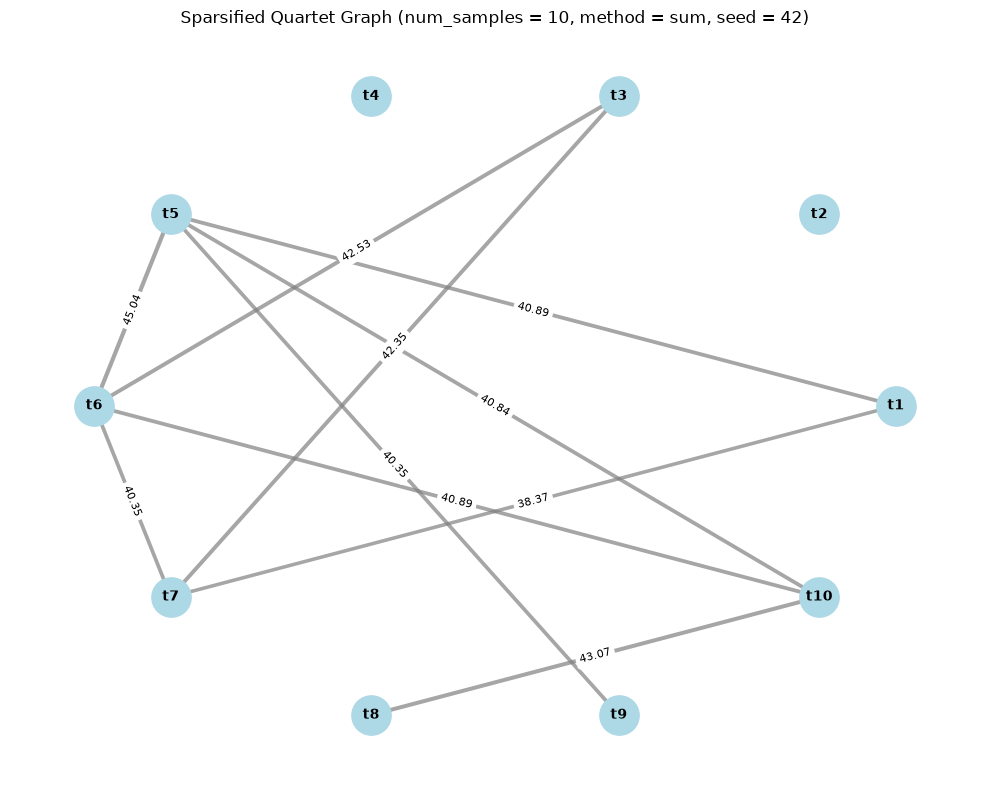

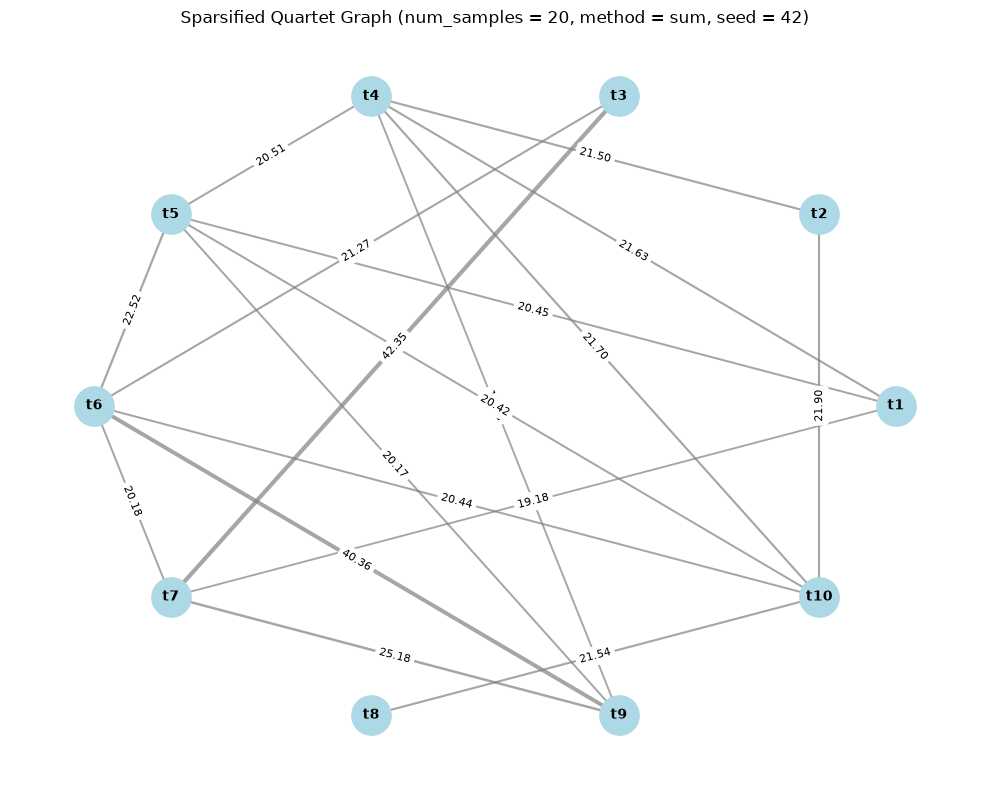

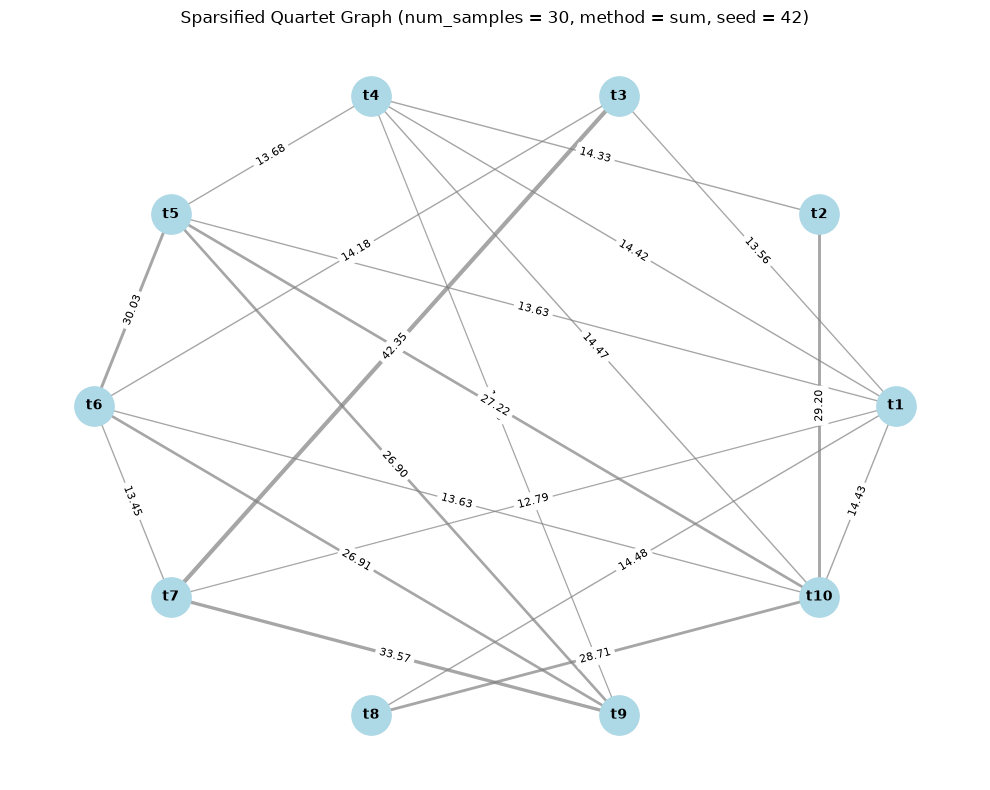

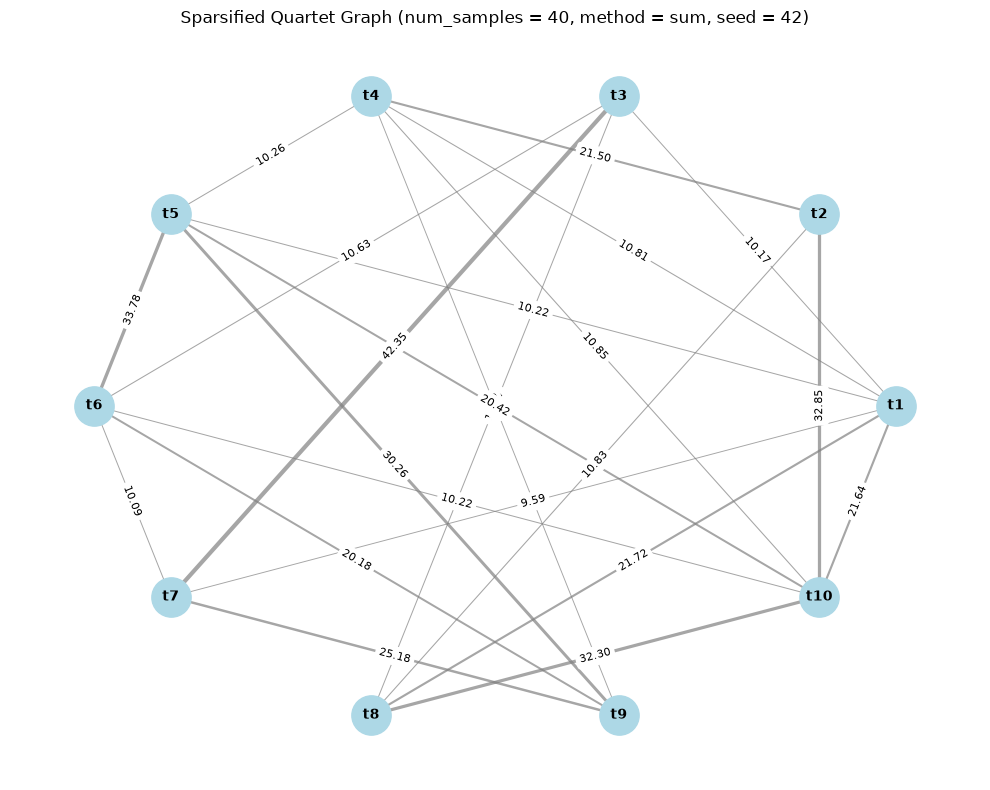

In [4]:
method = "sum"
seed = 42
for num_sample in [10, 20, 30, 40]:
    W = collapse_tensor(T, method)
    L = compute_laplacian(W)
    R = compute_effective_resistance(L)
    edge_list = compute_edge_sampling_probabilities(
        W, R, taxa
    )
    W_sparse = sample_edges(
        edge_list,
        num_samples=num_sample,
        n=len(taxa),
        taxa=taxa,
        seed=seed
    )
    visualize_graph(W_sparse, taxa, num_sample, method, seed)


Experiment 3 involves testing different seeds (0, 1 and 42)

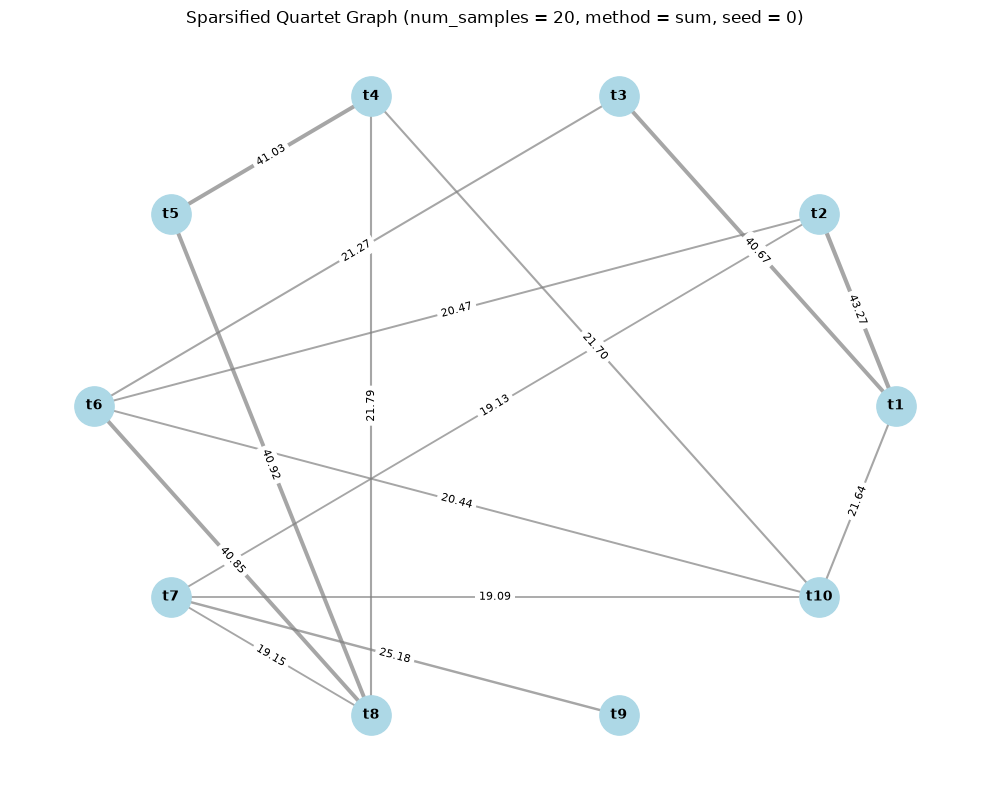

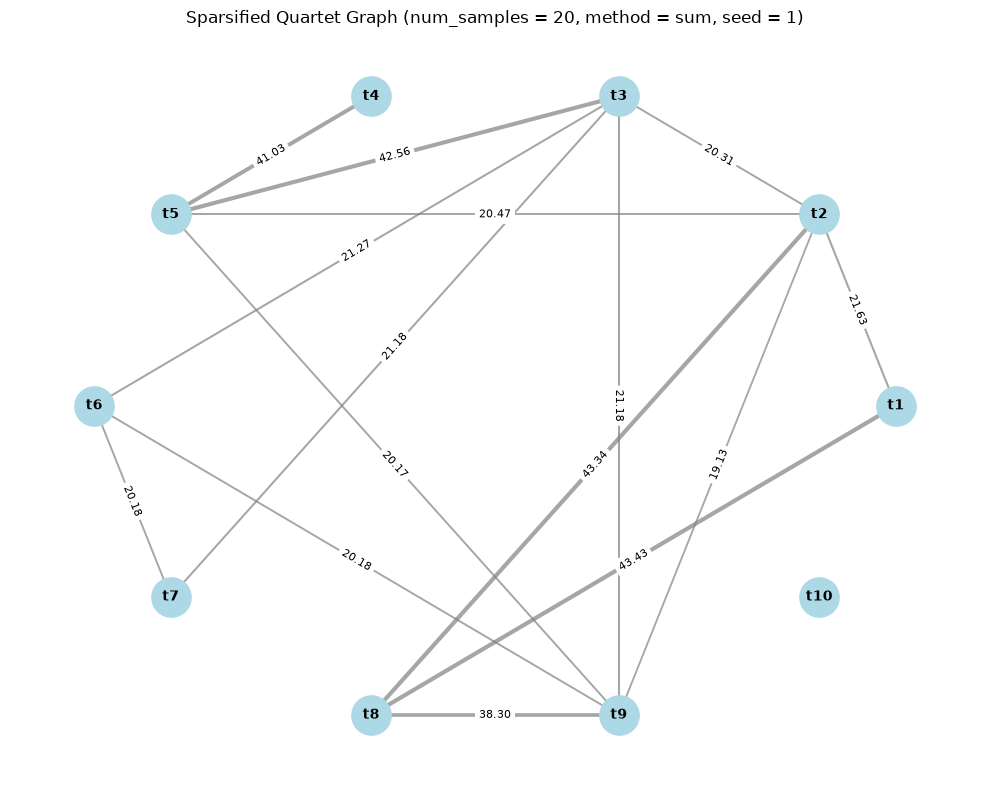

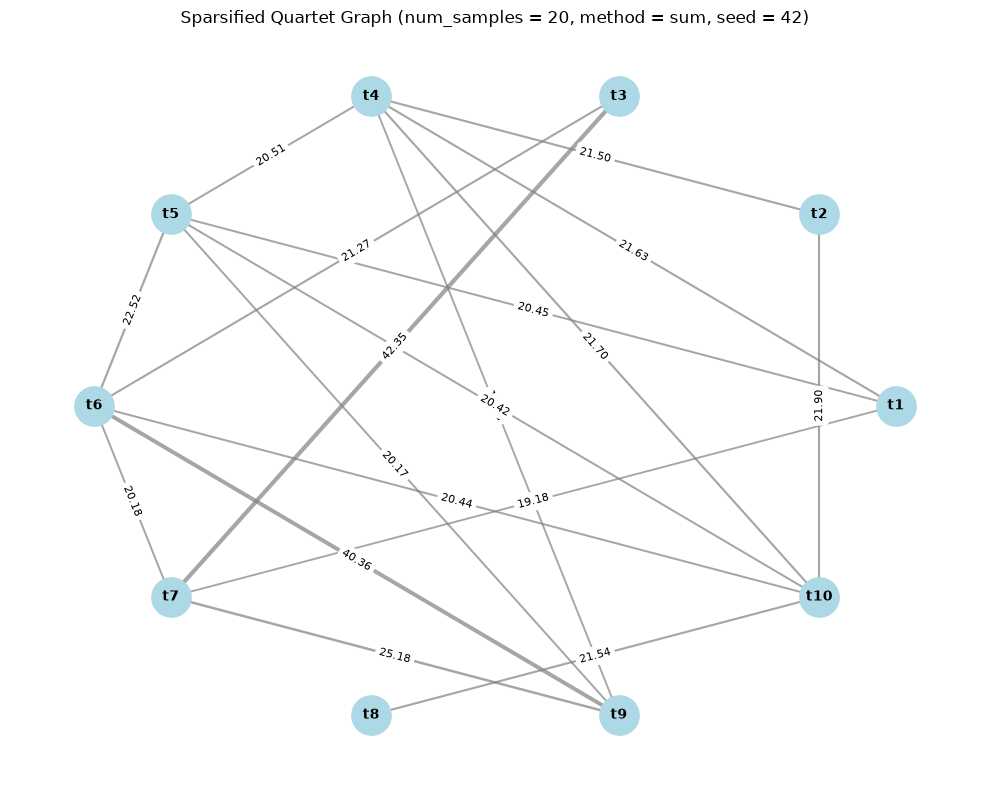

In [5]:
T, taxa = build_tensor(df)

method = "sum"
num_samples = 20

W = collapse_tensor(T, method)
L = compute_laplacian(W)
R = compute_effective_resistance(L)
edge_list = compute_edge_sampling_probabilities(W, R, taxa)

for seed in [0, 1, 42]:
    W_sparse = sample_edges(
        edge_list, num_samples, len(taxa), taxa, seed=seed
    )
    visualize_graph(W_sparse, taxa, num_samples, method, seed)

Experiment 4 - Run a bunch of different seeds using sum

In [6]:
T, taxa = build_tensor(df)

num_seeds = 1000
method = "sum"
num_samples = 20
W = collapse_tensor(T, method)
L = compute_laplacian(W)
R = compute_effective_resistance(L)
edge_list = compute_edge_sampling_probabilities(W, R, taxa)

# Start each original edge's retention count at zero
retention_counts = {
    (i, j): 0
    for i, j, w, r, s, p in edge_list
}

# Also keep the actual retained edges for each seed
edges_by_seed = {}
for seed in range(num_seeds):
    W_sparse = sample_edges(
        edge_list,
        num_samples=num_samples,
        n=len(taxa),
        taxa=taxa,
        seed=seed
    )
    retained = []
    for i, j in retention_counts:
        if W_sparse[i, j] > 0:
            retention_counts[(i, j)] += 1
            retained.append((taxa[i], taxa[j]))
    edges_by_seed[seed] = retained

# Build a summary table, including edges never retained
rows = []

for (i, j), count in retention_counts.items():
    rows.append({
        "edge": f"{taxa[i]}-{taxa[j]}",
        "runs_retained": count,
        "retention_percent": 100 * count / num_seeds
    })

retention_df = (
    pd.DataFrame(rows)
    .sort_values("runs_retained", ascending=False)
    .reset_index(drop=True)
)

print(retention_df.to_string(index=False))

  edge  runs_retained  retention_percent
 t7-t9            693               69.3
 t5-t6            487               48.7
 t4-t8            471               47.1
t2-t10            447               44.7
 t1-t2            445               44.5
t4-t10            445               44.5
 t2-t8            443               44.3
t1-t10            440               44.0
 t1-t8            433               43.3
 t3-t9            424               42.4
 t1-t4            423               42.3
t8-t10            419               41.9
 t3-t7            415               41.5
 t2-t4            409               40.9
 t3-t6            404               40.4
 t3-t5            397               39.7
 t6-t7            367               36.7
 t4-t5            367               36.7
 t1-t6            346               34.6
 t5-t9            340               34.0
 t2-t3            337               33.7
 t6-t9            337               33.7
t3-t10            334               33.4
t6-t10          

Experiment 5 - Run a bunch of different seeds using max

In [7]:
T, taxa = build_tensor(df)

num_seeds = 1000
method = "max"
num_samples = 20
W = collapse_tensor(T, method)
L = compute_laplacian(W)
R = compute_effective_resistance(L)
edge_list = compute_edge_sampling_probabilities(W, R, taxa)

# Start each original edge's retention count at zero
retention_counts = {
    (i, j): 0
    for i, j, w, r, s, p in edge_list
}

# Also keep the actual retained edges for each seed
edges_by_seed = {}
for seed in range(num_seeds):
    W_sparse = sample_edges(
        edge_list,
        num_samples=num_samples,
        n=len(taxa),
        taxa=taxa,
        seed=seed
    )
    retained = []
    for i, j in retention_counts:
        if W_sparse[i, j] > 0:
            retention_counts[(i, j)] += 1
            retained.append((taxa[i], taxa[j]))
    edges_by_seed[seed] = retained

# Build a summary table, including edges never retained
rows = []

for (i, j), count in retention_counts.items():
    rows.append({
        "edge": f"{taxa[i]}-{taxa[j]}",
        "runs_retained": count,
        "retention_percent": 100 * count / num_seeds
    })

retention_df = (
    pd.DataFrame(rows)
    .sort_values("runs_retained", ascending=False)
    .reset_index(drop=True)
)

print(retention_df.to_string(index=False))

  edge  runs_retained  retention_percent
 t7-t9            521               52.1
t3-t10            416               41.6
t5-t10            415               41.5
 t1-t6            411               41.1
 t1-t2            406               40.6
t4-t10            401               40.1
 t1-t3            401               40.1
 t4-t5            397               39.7
 t4-t6            396               39.6
 t2-t6            396               39.6
 t2-t3            396               39.6
t1-t10            396               39.6
 t1-t8            396               39.6
 t2-t5            395               39.5
 t2-t4            388               38.8
 t5-t8            386               38.6
 t3-t5            385               38.5
t2-t10            384               38.4
t8-t10            384               38.4
t6-t10            383               38.3
 t3-t6            381               38.1
 t1-t5            379               37.9
 t1-t4            378               37.8
 t4-t8          

Experiment 6 - Run a bunch of different seeds using mean

In [8]:
T, taxa = build_tensor(df)

num_seeds = 1000
method = "mean"
num_samples = 20
W = collapse_tensor(T, method)
L = compute_laplacian(W)
R = compute_effective_resistance(L)
edge_list = compute_edge_sampling_probabilities(W, R, taxa)

# Start each original edge's retention count at zero
retention_counts = {
    (i, j): 0
    for i, j, w, r, s, p in edge_list
}

# Also keep the actual retained edges for each seed
edges_by_seed = {}
for seed in range(num_seeds):
    W_sparse = sample_edges(
        edge_list,
        num_samples=num_samples,
        n=len(taxa),
        taxa=taxa,
        seed=seed
    )
    retained = []
    for i, j in retention_counts:
        if W_sparse[i, j] > 0:
            retention_counts[(i, j)] += 1
            retained.append((taxa[i], taxa[j]))
    edges_by_seed[seed] = retained

# Build a summary table, including edges never retained
rows = []

for (i, j), count in retention_counts.items():
    rows.append({
        "edge": f"{taxa[i]}-{taxa[j]}",
        "runs_retained": count,
        "retention_percent": 100 * count / num_seeds
    })

retention_df = (
    pd.DataFrame(rows)
    .sort_values("runs_retained", ascending=False)
    .reset_index(drop=True)
)

print(retention_df.to_string(index=False))

  edge  runs_retained  retention_percent
 t7-t9            693               69.3
 t5-t6            487               48.7
 t4-t8            471               47.1
t2-t10            447               44.7
 t1-t2            445               44.5
t4-t10            445               44.5
 t2-t8            443               44.3
t1-t10            440               44.0
 t1-t8            433               43.3
 t3-t9            424               42.4
 t1-t4            423               42.3
t8-t10            419               41.9
 t3-t7            415               41.5
 t2-t4            409               40.9
 t3-t6            404               40.4
 t3-t5            397               39.7
 t6-t7            367               36.7
 t4-t5            367               36.7
 t1-t6            346               34.6
 t5-t9            340               34.0
 t2-t3            337               33.7
 t6-t9            337               33.7
t3-t10            334               33.4
t6-t10          

Experiment 7 - Run a bunch of different seeds using l2

In [9]:
T, taxa = build_tensor(df)

num_seeds = 1000
method = "l2"
num_samples = 20
W = collapse_tensor(T, method)
L = compute_laplacian(W)
R = compute_effective_resistance(L)
edge_list = compute_edge_sampling_probabilities(W, R, taxa)

# Start each original edge's retention count at zero
retention_counts = {
    (i, j): 0
    for i, j, w, r, s, p in edge_list
}

# Also keep the actual retained edges for each seed
edges_by_seed = {}
for seed in range(num_seeds):
    W_sparse = sample_edges(
        edge_list,
        num_samples=num_samples,
        n=len(taxa),
        taxa=taxa,
        seed=seed
    )
    retained = []
    for i, j in retention_counts:
        if W_sparse[i, j] > 0:
            retention_counts[(i, j)] += 1
            retained.append((taxa[i], taxa[j]))
    edges_by_seed[seed] = retained

# Build a summary table, including edges never retained
rows = []

for (i, j), count in retention_counts.items():
    rows.append({
        "edge": f"{taxa[i]}-{taxa[j]}",
        "runs_retained": count,
        "retention_percent": 100 * count / num_seeds
    })

retention_df = (
    pd.DataFrame(rows)
    .sort_values("runs_retained", ascending=False)
    .reset_index(drop=True)
)

print(retention_df.to_string(index=False))

  edge  runs_retained  retention_percent
 t7-t9            655               65.5
 t4-t8            457               45.7
 t5-t6            454               45.4
 t1-t2            437               43.7
t1-t10            433               43.3
 t2-t8            432               43.2
t4-t10            431               43.1
 t3-t9            428               42.8
 t1-t8            424               42.4
t2-t10            419               41.9
 t3-t7            418               41.8
 t1-t4            418               41.8
t8-t10            416               41.6
 t3-t6            403               40.3
 t2-t4            397               39.7
 t3-t5            380               38.0
 t6-t7            378               37.8
 t4-t5            366               36.6
 t6-t9            355               35.5
 t5-t9            355               35.5
 t5-t7            345               34.5
 t1-t6            343               34.3
 t2-t3            340               34.0
t3-t10          

## Edge Retention and Weight Stability Across Random Seeds

Run sparsification across multiple seeds with a fixed sample count, tracking each edge’s retention frequency and mean sampled weight using method = "sum".

In [10]:
df = pd.read_csv("tree_cfs.csv")
T, taxa = build_tensor(df)

num_seeds = 1000
method = "sum"
num_samples = 20

W = collapse_tensor(T, method)
L = compute_laplacian(W)
R = compute_effective_resistance(L)
edge_list = compute_edge_sampling_probabilities(W, R, taxa)

# Each edge gets a list containing its weight from every run
weights_by_edge = {
    (i, j): []
    for i, j, w, r, s, p in edge_list
}

for seed in range(num_seeds):
    W_sparse = sample_edges(
        edge_list,
        num_samples=num_samples,
        n=len(taxa),
        taxa=taxa,
        seed=seed
    )

    for i, j in weights_by_edge:
        # Includes zero when the edge wasn't retained
        weights_by_edge[(i, j)].append(W_sparse[i, j])

# Summarize results for each edge
rows = []

for (i, j), weights in weights_by_edge.items():
    weights = np.array(weights)
    count = np.count_nonzero(weights > 0)

    rows.append({
        "edge": f"{taxa[i]}-{taxa[j]}",
        "runs_retained": count,
        "retention_percent": 100 * count / num_seeds,
        "original_weight": W[i, j],
        "total_weight": np.sum(weights),
        "mean_weight": np.mean(weights)
    })

weight_df = (
    pd.DataFrame(rows)
    .sort_values("mean_weight", ascending=False)
    .reset_index(drop=True)
)

print(weight_df.round(3).to_string(index=False))

  edge  runs_retained  retention_percent  original_weight  total_weight  mean_weight
 t7-t9            693               69.3           27.909     29334.145       29.334
 t5-t6            487               48.7           16.093     14841.086       14.841
 t4-t8            471               47.1           12.830     13463.152       13.463
t2-t10            447               44.7           13.349     13009.750       13.010
 t1-t2            445               44.5           12.156     12806.684       12.807
 t2-t8            443               44.3           12.327     12545.966       12.546
t4-t10            445               44.5           12.484     12197.157       12.197
t1-t10            440               44.0           12.202     12163.046       12.163
 t3-t7            415               41.5           11.884     11964.963       11.965
 t1-t8            433               43.3           12.517     11856.471       11.856
t8-t10            419               41.9           11.721     116

Using method = "max" 

In [11]:
df = pd.read_csv("tree_cfs.csv")
T, taxa = build_tensor(df)

num_seeds = 1000
method = "max"
num_samples = 20

# Build the original graph and sampling probabilities once
W = collapse_tensor(T, method)
L = compute_laplacian(W)
R = compute_effective_resistance(L)
edge_list = compute_edge_sampling_probabilities(W, R, taxa)

# Each edge gets a list containing its weight from every run
weights_by_edge = {
    (i, j): []
    for i, j, w, r, s, p in edge_list
}

for seed in range(num_seeds):
    W_sparse = sample_edges(
        edge_list,
        num_samples=num_samples,
        n=len(taxa),
        taxa=taxa,
        seed=seed
    )

    for i, j in weights_by_edge:
        # Includes zero when the edge wasn't retained
        weights_by_edge[(i, j)].append(W_sparse[i, j])

# Summarize results for each edge
rows = []

for (i, j), weights in weights_by_edge.items():
    weights = np.array(weights)
    count = np.count_nonzero(weights > 0)

    rows.append({
        "edge": f"{taxa[i]}-{taxa[j]}",
        "runs_retained": count,
        "retention_percent": 100 * count / num_seeds,
        "original_weight": W[i, j],
        "total_weight": np.sum(weights),
        "mean_weight": np.mean(weights)
    })

weight_df = (
    pd.DataFrame(rows)
    .sort_values("mean_weight", ascending=False)
    .reset_index(drop=True)
)

print(weight_df.round(3).to_string(index=False))

  edge  runs_retained  retention_percent  original_weight  total_weight  mean_weight
t3-t10            416               41.6            0.997      1077.079        1.077
 t1-t2            406               40.6            0.997      1058.757        1.059
 t7-t9            521               52.1            1.000      1052.212        1.052
 t4-t5            397               39.7            0.996      1044.761        1.045
 t2-t5            395               39.5            0.998      1030.867        1.031
t5-t10            415               41.5            0.997      1018.920        1.019
 t1-t3            401               40.1            0.997      1015.914        1.016
 t1-t6            411               41.1            0.996      1009.957        1.010
 t5-t8            386               38.6            0.998      1009.332        1.009
 t2-t3            396               39.6            0.996      1006.835        1.007
 t3-t6            381               38.1            0.995      10

Using method = "mean"

In [12]:
df = pd.read_csv("tree_cfs.csv")
T, taxa = build_tensor(df)

num_seeds = 1000
method = "mean"
num_samples = 20

W = collapse_tensor(T, method)
L = compute_laplacian(W)
R = compute_effective_resistance(L)
edge_list = compute_edge_sampling_probabilities(W, R, taxa)

# Each edge gets a list containing its weight from every run
weights_by_edge = {
    (i, j): []
    for i, j, w, r, s, p in edge_list
}

for seed in range(num_seeds):
    W_sparse = sample_edges(
        edge_list,
        num_samples=num_samples,
        n=len(taxa),
        taxa=taxa,
        seed=seed
    )

    for i, j in weights_by_edge:
        # Includes zero when the edge wasn't retained
        weights_by_edge[(i, j)].append(W_sparse[i, j])

# Summarize results for each edge
rows = []

for (i, j), weights in weights_by_edge.items():
    weights = np.array(weights)
    count = np.count_nonzero(weights > 0)

    rows.append({
        "edge": f"{taxa[i]}-{taxa[j]}",
        "runs_retained": count,
        "retention_percent": 100 * count / num_seeds,
        "original_weight": W[i, j],
        "total_weight": np.sum(weights),
        "mean_weight": np.mean(weights)
    })

weight_df = (
    pd.DataFrame(rows)
    .sort_values("mean_weight", ascending=False)
    .reset_index(drop=True)
)

print(weight_df.round(3).to_string(index=False))

  edge  runs_retained  retention_percent  original_weight  total_weight  mean_weight
 t7-t9            693               69.3            0.133       139.686        0.140
 t5-t6            487               48.7            0.077        70.672        0.071
 t4-t8            471               47.1            0.061        64.110        0.064
t2-t10            447               44.7            0.064        61.951        0.062
 t1-t2            445               44.5            0.058        60.984        0.061
 t2-t8            443               44.3            0.059        59.743        0.060
t4-t10            445               44.5            0.059        58.082        0.058
t1-t10            440               44.0            0.058        57.919        0.058
 t3-t7            415               41.5            0.057        56.976        0.057
 t1-t8            433               43.3            0.060        56.459        0.056
t8-t10            419               41.9            0.056        

Using method = "l2"

In [13]:
df = pd.read_csv("tree_cfs.csv")
T, taxa = build_tensor(df)

num_seeds = 1000
method = "l2"
num_samples = 20

W = collapse_tensor(T, method)
L = compute_laplacian(W)
R = compute_effective_resistance(L)
edge_list = compute_edge_sampling_probabilities(W, R, taxa)

# Each edge gets a list containing its weight from every run
weights_by_edge = {
    (i, j): []
    for i, j, w, r, s, p in edge_list
}

for seed in range(num_seeds):
    W_sparse = sample_edges(
        edge_list,
        num_samples=num_samples,
        n=len(taxa),
        taxa=taxa,
        seed=seed
    )

    for i, j in weights_by_edge:
        # Includes zero when the edge wasn't retained
        weights_by_edge[(i, j)].append(W_sparse[i, j])

# Summarize results for each edge
rows = []

for (i, j), weights in weights_by_edge.items():
    weights = np.array(weights)
    count = np.count_nonzero(weights > 0)

    rows.append({
        "edge": f"{taxa[i]}-{taxa[j]}",
        "runs_retained": count,
        "retention_percent": 100 * count / num_seeds,
        "original_weight": W[i, j],
        "total_weight": np.sum(weights),
        "mean_weight": np.mean(weights)
    })

weight_df = (
    pd.DataFrame(rows)
    .sort_values("mean_weight", ascending=False)
    .reset_index(drop=True)
)

print(weight_df.round(3).to_string(index=False))

  edge  runs_retained  retention_percent  original_weight  total_weight  mean_weight
 t7-t9            655               65.5            5.274      5563.077        5.563
 t5-t6            454               45.4            3.103      2885.054        2.885
 t4-t8            457               45.7            2.568      2699.225        2.699
 t3-t7            418               41.8            2.623      2594.512        2.595
 t1-t2            437               43.7            2.452      2594.197        2.594
t2-t10            419               41.9            2.643      2525.315        2.525
 t3-t9            428               42.8            2.623      2520.646        2.521
 t2-t8            432               43.2            2.483      2515.724        2.516
t1-t10            433               43.3            2.473      2476.572        2.477
t4-t10            431               43.1            2.513      2450.274        2.450
t8-t10            416               41.6            2.392      24